# Introduction

This data concerns a Telecom provider's customer database reporting on who has churned and who has not. This allows us to build a predictive model to classify churners and non-churners in the future. We will build our own cross-validation pipeline using a training and test set which we will create ourselves. Furthermore, we will apply multiple predictive pipelines and perform a grid search to optimise the parameters of the algorithms used.

The original data can be found here:
https://www.kaggle.com/datasets/blastchar/telco-customer-churn
It contains a number of variables, most of which are self-explanatory.

Let's have a first look at the data below:

In [51]:
import pandas as pd
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CHURN_PATH = "data/Telco-Churn.csv" if os.path.exists("data/Telco-Churn.csv") else "../data/Telco-Churn.csv"
df = pd.read_csv(CHURN_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


We ask for a description of the numeric variables:

In [27]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


We can also do this for the categorical ones:

In [28]:
df.describe(include='object')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


This dataset contains a high number of categorical variables and only a few numeric ones. The label is the binary variable 'Churn' ('Yes'/'No').

It appears the dataset is unbalanced:

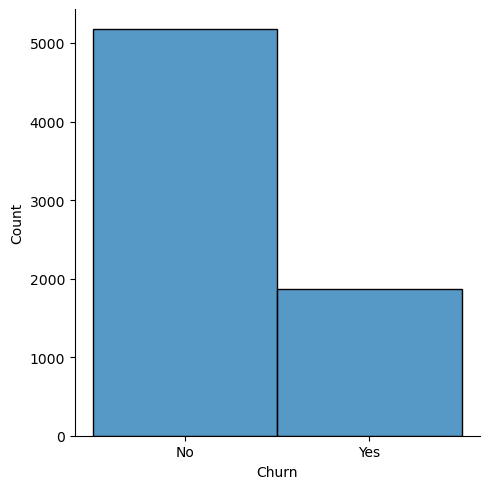

In [29]:
import seaborn as sns

sns.displot(df, x='Churn')

There are more non-churners than churners. This is something to bear in mind later during the evaluation stage.

# Data pre-processing

Let's have a look at the different variables and their data types:

In [30]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

It appears that 'TotalCharges' is listed as a categorical value, despite it containg numbers at first sight. We will have to remedy this.

We have also seen before that there are many variables with a high number of unique values. As expected, 'customerID' has all unique values, we will remove this variable similar to the previous notebook. The numeric variable 'MonthlyCharges' also has many unique values, which is normal for this variable type. We will have to address the problem with 'TotalCharges' first. Using Pandas, we can convert 'TotalCharges'. We use option `errors` set to `coerce` to add `NaN` on the missing lines of data which contain whitespaces which caused Pandas to list 'TotalCharges' as a categorical variable to begin with. We also drop 'customerID':

In [31]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [32]:
df = df.drop(['customerID'], axis=1)

Before we create a train and test split, we first still convert the categorical variables into dummies as done below:

In [33]:
print('Number of columns before:', len(df.columns))
df_clean = pd.get_dummies(df)
print('Number of columns after:', len(df_clean.columns))

Number of columns before: 20
Number of columns after: 47


We now have 47 variables instead of 20, which is still a reasonable amount. We will now look at missing values by checking which columns contain `NaN` values:

In [34]:
for column in df_clean.columns:
  if df_clean[column].isna().sum() > 0:
    print('Column:', column)
    print(df_clean[column].isna().sum())

Column: TotalCharges
11


# Validation setup

We will make use of a training and test set. The training set will be used for a cross-validation where we use a number of training/validation sets to choose the best-performing parameters and models for our data. Then, we will use the test set as the unbiased evaluator at the end.

Luckily, scikit-learn has an easy built-in function for creating training and test sets as per below:

In [35]:
from sklearn.model_selection import train_test_split

# create the dependent and independent DataFrame
y = df_clean['Churn_Yes']
X = df_clean.drop(['Churn_Yes', 'Churn_No'], axis=1)

# create the training and test sets:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
print('Number of observations in initial dataset:\t', len(X))
print('Number of observations in the training set:\t', len(X_train))
print('Number of observations in the test set:\t\t', len(X_test))

Number of observations in initial dataset:	 7043
Number of observations in the training set:	 4930
Number of observations in the test set:		 2113


First we address the missing values. Instead of Pandas, we will now use the `SimpleImputer` from scikit-learn instead. It has similar functionality and fills empty cells in numeric columns with the mean (adjustable through its parameters, see https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html). In order for it to work, however, all variables need to be numeric already.
Again, we first learn what to impute on the training set and apply it to the test set afterwards.

Note that, whenever scikit-learn is used over a Pandas DataFrame, it returns just the values in a NumPy matrix. We reconstruct the DataFrame with a new DataFrame with the raw data we get from the imputer and add the original column names:

In [36]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer()
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
# here we create a new DataFrame with the columns of our initial dataset
# as scikit-learn output is always composed of the raw values instead of
# a metadata-enriched Pandas DataFrame
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)
X_train

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,13.0,45.30,528.45,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,35.0,70.55,2419.00,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,74.90,74.90,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,1.0,46.30,46.30,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,40.0,104.50,4036.85,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4925,0.0,72.0,92.00,6632.75,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
4926,0.0,18.0,94.75,1691.90,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4927,0.0,10.0,20.45,242.40,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4928,0.0,12.0,29.20,309.10,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


This time, we will apply a min-max normalisation as per $\frac{X_i - min}{max - min}$ with $X_i$ the observation and $min$ and $max$ the minimum and maximum value of variable $i$ respectively. This can once again be done with scikit-learn. We first 'fit' the training data and then transform the training data accordingly. We will use the parameters learned on the training dataset (the minimum and maximum) to transform our test set in an unbiased way as well. Once again, it is also necessary to recreate the DataFrames:

In [37]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = scaler.transform(X_test)
X_test = pd.DataFrame(X_test, columns=X.columns)
X_train

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1.0,0.180556,0.269154,0.058810,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.486111,0.520398,0.276967,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.013889,0.563682,0.006474,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.013889,0.279104,0.003173,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.555556,0.858209,0.463657,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4925,0.0,1.000000,0.733831,0.763207,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
4926,0.0,0.250000,0.761194,0.193065,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4927,0.0,0.138889,0.021891,0.025802,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4928,0.0,0.166667,0.108955,0.033499,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


# Feature selection

We have 47 variables in total, which is not a very high number given that some problems use millions of variables with suitable architectures such as neural networks. However, we will briefly look into feature selection using the entropy-based mutual information criterion which measures the correlation between a variable and the label. Again, we use scikit-learn and first calculate the score to get a grasp of the important variables:

In [38]:
from sklearn.feature_selection import mutual_info_classif

mic = mutual_info_classif(X_train, y_train)
for column, mic in zip(X_train.columns, mic):
  print(column, 'has a MIC of %.3f' % mic)

SeniorCitizen has a MIC of 0.014
tenure has a MIC of 0.076
MonthlyCharges has a MIC of 0.041
TotalCharges has a MIC of 0.043
gender_Female has a MIC of 0.000
gender_Male has a MIC of 0.000
Partner_No has a MIC of 0.004
Partner_Yes has a MIC of 0.015
Dependents_No has a MIC of 0.011
Dependents_Yes has a MIC of 0.014
PhoneService_No has a MIC of 0.004
PhoneService_Yes has a MIC of 0.005
MultipleLines_No has a MIC of 0.000
MultipleLines_No phone service has a MIC of 0.004
MultipleLines_Yes has a MIC of 0.004
InternetService_DSL has a MIC of 0.008
InternetService_Fiber optic has a MIC of 0.048
InternetService_No has a MIC of 0.036
OnlineSecurity_No has a MIC of 0.059
OnlineSecurity_No internet service has a MIC of 0.026
OnlineSecurity_Yes has a MIC of 0.018
OnlineBackup_No has a MIC of 0.042
OnlineBackup_No internet service has a MIC of 0.032
OnlineBackup_Yes has a MIC of 0.000
DeviceProtection_No has a MIC of 0.041
DeviceProtection_No internet service has a MIC of 0.021
DeviceProtection_Y

It appears there are plenty of informative variables present (with a score above 0, the score can mostly be used to compare variables, not to interpret its magnitude). We can select the ones with the highest score accordingly. Notice that the `fit` and `fit_transform` functions are common to all scikit-learn (pre)processing steps, similar to the decision tree we built earlier, and the imputer we used.

In [39]:
from sklearn.feature_selection import SelectKBest

# select the KBest based on mutual information
kbest = SelectKBest(mutual_info_classif, k=20)
kbest.fit(X_train, y_train)
# we loop all columns and whether they were chosen by the algorithm
# we can request this by the .get_support() function which returns an array
# of booleans as long as the number of columns to indicate whether they were
# selected:
selected_columns = []
for col, select in zip(X_train.columns, kbest.get_support()):
  if select:
    print(col, 'is selected')
    # we store them separately to use in our new DataFrames below
    selected_columns.append(col)
# now we apply this to both train and test set
# again, the test set is treated according to the insights obtained
# from the training set
X_train = kbest.transform(X_train)
X_test = kbest.transform(X_test)
X_train = pd.DataFrame(X_train, columns=selected_columns)
X_test = pd.DataFrame(X_test, columns=selected_columns)
X_train

tenure is selected
MonthlyCharges is selected
TotalCharges is selected
InternetService_Fiber optic is selected
InternetService_No is selected
OnlineSecurity_No is selected
OnlineSecurity_No internet service is selected
OnlineBackup_No is selected
OnlineBackup_No internet service is selected
DeviceProtection_No is selected
DeviceProtection_No internet service is selected
TechSupport_No is selected
TechSupport_No internet service is selected
StreamingTV_No internet service is selected
StreamingMovies_No internet service is selected
Contract_Month-to-month is selected
Contract_Two year is selected
PaperlessBilling_No is selected
PaperlessBilling_Yes is selected
PaymentMethod_Electronic check is selected


,tenure,MonthlyCharges,TotalCharges,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineBackup_No,OnlineBackup_No internet service,DeviceProtection_No,DeviceProtection_No internet service,TechSupport_No,TechSupport_No internet service,StreamingTV_No internet service,StreamingMovies_No internet service,Contract_Month-to-month,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Electronic check
0,0.180556,0.269154,0.058810,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
1,0.486111,0.520398,0.276967,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2,0.013889,0.563682,0.006474,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
3,0.013889,0.279104,0.003173,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,0.555556,0.858209,0.463657,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4925,1.000000,0.733831,0.763207,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4926,0.250000,0.761194,0.193065,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
4927,0.138889,0.021891,0.025802,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4928,0.166667,0.108955,0.033499,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


# Classification

Now we will perform our classification. In this instance we will use a random forest, however, note that the usage is identical to the way we applied a simple decision tree in the previous notebook. Hence, all classifiers are interchangeable.

We will first build the forest using the training data and then apply it to the test set. We obtain predictions using the `predict` and `predict_proba` functions. The former returns a label, and the latter provides a probability per label class (in this case there are 2 as we have a binary classification). Some algorithms return a probability naturally (such as neural networks before softmax, or a naive Bayesian approach), others need some assistance (such as SVMs or decision trees). We need the probabilities in order to calculate the area under receiver operation characteristics curve (AUC), as it needs the probabilities to find the different thresholds:

In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, roc_auc_score

rf = RandomForestClassifier(n_estimators=50, max_depth=3)
rf.fit(X_train, y_train)
predictions = rf.predict(X_train)
predictions_prob = rf.predict_proba(X_train)
predictions_test = rf.predict(X_test)
predictions_test_prob = rf.predict_proba(X_test)

print("Precision: %.3f" % precision_score(y_train, predictions))
print("Recall: %.3f" % recall_score(y_train, predictions))
print("AUC: %.3f" % roc_auc_score(y_train, predictions_prob[:,1]))
print("Precision test: %.3f" % precision_score(y_test, predictions_test))
print("Recall test: %.3f" % recall_score(y_test, predictions_test))
print("AUC test: %.3f" % roc_auc_score(y_test, predictions_test_prob[:,1]))

Precision: 0.715
Recall: 0.383
AUC: 0.852
Precision test: 0.710
Recall test: 0.376
AUC test: 0.825


The results of both training and test sets are comparable, meaning the algorithm is doing a good job of transferring the insights obtained from the training set to the unseen test data. Given the inbalance, AUC is the more appropriate evaluation metric and it appears that good AUC can be had at 85%. We can visualise this again as follows:

Text(0, 0.5, 'True Positive Rate (TPR)')

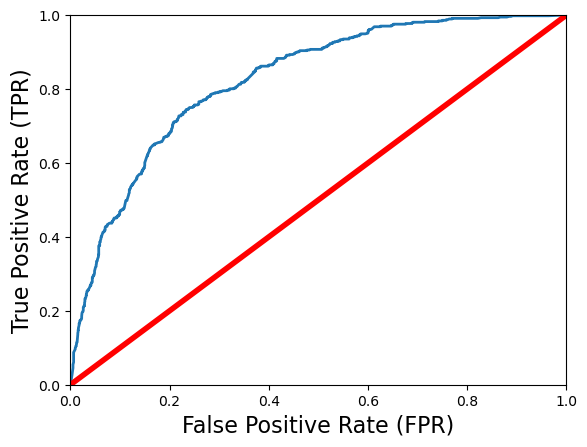

In [41]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test, predictions_test_prob[:,1])

plt.plot(false_positive_rate, true_positive_rate, linewidth=2)
plt.plot([0, 1], [0, 1], 'r', linewidth=4)
plt.axis([0, 1, 0, 1])
plt.xlabel('False Positive Rate (FPR)', fontsize=16)
plt.ylabel('True Positive Rate (TPR)', fontsize=16)

# Interpretation

You can obtain the most important variables, for tree-based models typically the average reduction in Gini per variable.

In [42]:
for column, fi in zip(X_train.columns, rf.feature_importances_):
  print('Column', column, 'has feature importance:', fi)

Column tenure has feature importance: 0.18302209776578987
Column MonthlyCharges has feature importance: 0.02862013180316704
Column TotalCharges has feature importance: 0.08547412977655418
Column InternetService_Fiber optic has feature importance: 0.12986947584110203
Column InternetService_No has feature importance: 0.020158118245756213
Column OnlineSecurity_No has feature importance: 0.15851943750759903
Column OnlineSecurity_No internet service has feature importance: 0.002343283880429544
Column OnlineBackup_No has feature importance: 0.027756397083484208
Column OnlineBackup_No internet service has feature importance: 0.001699453121582305
Column DeviceProtection_No has feature importance: 0.002797012741805924
Column DeviceProtection_No internet service has feature importance: 0.007868515918186117
Column TechSupport_No has feature importance: 0.09554470528994169
Column TechSupport_No internet service has feature importance: 0.0
Column StreamingTV_No internet service has feature importan

It appears that the 'Contract_Month-to-month' variables, followed by the 'TechSupport_No', 'tenure', and 'OnlineSecurity_No' features have the highest impact on the classification. Note that we do not know the direction of the impact, however (i.e., whether this creates a higher or lower chance). Fun exercise: try to implement Shapley values yourself (https://github.com/slundberg/shap).

# Cross-validation and pipelining

As mentioned earlier, we also want to be able to perform cross-validation to adequately evaluate different settings of our pre-processing and model-building approach. We can simply apply a classifier with cross-validation using the `cross_val_score` function. We obtain the AUC for the 10 different folds as follows:

In [43]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score

scores = cross_val_score(rf, X_train, y_train, cv=10, scoring='roc_auc')
# the result is a NumPy array
scores

array([0.84226723, 0.87140089, 0.83891302, 0.85456665, 0.84093028,
       0.82578936, 0.86171858, 0.83907608, 0.82841704, 0.85768171])

In [44]:
import numpy as np

# we can obtain the mean as follows
print('Mean AUC:', np.mean(scores))

Mean AUC: 0.8460760838879233


The default scoring is accuracy, and other evaluation approaches are available as well (see: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html), but hear we explicitly asked for the 'roc_auc' using the 'scoring' argument.

Next, let's see how we can recreate the whole pipeline of all our pre-processing steps and classification using pipelines. They make it easy to fit all the steps on the training data at once and then to apply all the steps with their learned parameters on the test set. Below, a pipeline is created which includes the standard scaling, feature selection, and classifier we used before. It is very easy to add different steps as well. Once the pipe is created, it can be `fit()` function just like the separate steps, and applied using the `transform()` function on the test set eventually. Let's explore a few pipelines with slightly different parameters for its components:

In [45]:
from sklearn.pipeline import Pipeline
import numpy as np

# we once again make our split so we can start from our untouched data
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X, y, test_size=0.3)

pipe_1 = Pipeline([('imputation', SimpleImputer()), ('scaling', MinMaxScaler()),('feature_selection', SelectKBest(mutual_info_classif, k=20)),
                 ('classifier', RandomForestClassifier(n_estimators=50, max_depth=3))])
scores = cross_val_score(pipe_1, X_train, y_train, cv=10, scoring='roc_auc')
print('Average AUC: %.3f' % np.mean(scores))

Average AUC: 0.846


In [46]:
pipe_2 = Pipeline([('imputation', SimpleImputer()), ('scaling', MinMaxScaler()),('feature_selection', SelectKBest(mutual_info_classif, k=30)),
                 ('classifier', RandomForestClassifier(n_estimators=50, max_depth=3))])
scores = cross_val_score(pipe_2, X_train_2, y_train_2, cv=10, scoring='roc_auc')
print('Average AUC: %.3f' % np.mean(scores))

Average AUC: 0.834


In [47]:
pipe_3 = Pipeline([('imputation', SimpleImputer()), ('scaling', MinMaxScaler()),('feature_selection', SelectKBest(mutual_info_classif, k=40)),
                 ('classifier', RandomForestClassifier(n_estimators=200, max_depth=7))])
scores = cross_val_score(pipe_3, X_train_2, y_train_2, cv=10, scoring='roc_auc')
print('Average AUC: %.3f' % np.mean(scores))

Average AUC: 0.845


It seems pipe 3 works best. We will now fit it again with the whole training set and apply it to the unseen data of the test set. The performance remains rougly the same compared to our initial model. It seems the parameters have limited impact on the performance:

In [48]:
pipe_3.fit(X_train_2, y_train_2)
predictions_test = pipe_3.predict(X_test_2)
predictions_test_prob = pipe_3.predict_proba(X_test_2)

print("Precision test: %.3f" % precision_score(y_test_2, predictions_test))
print("Recall test: %.3f" % recall_score(y_test_2, predictions_test))
print("AUC test: %.3f" % roc_auc_score(y_test_2, predictions_test_prob[:,1]))

Precision test: 0.693
Recall test: 0.482
AUC test: 0.852


Finally, we can also facilitate this whole parameter search using a grid search in combination with a cross-validation. To this purpose, we use the `GridSearchCV` which requires a classifier or pipeline and a dictionary containing the parameters (use the pipeline step name + parameter name concatenated by 2 underscores) and the range of values you want to use in a list. Below, we try 3 different values for the $K$-number of variables to retain by the feature selection procedure, the number of trees to use in the random forest, and the maximum depth of the trees in the forest:

In [49]:
from sklearn.model_selection import GridSearchCV

pipe_cv = Pipeline([('imputation', SimpleImputer()), ('scaling', MinMaxScaler()),('feature_selection', SelectKBest()),
                 ('classifier', RandomForestClassifier())])
param_grid = {'feature_selection__k': [10, 20, 40], 'classifier__n_estimators': [10, 50, 100], 'classifier__max_depth': [5, 10]}

# 10-fold CV is used
search = GridSearchCV(pipe_cv, param_grid, scoring='roc_auc', cv=10)
search.fit(X_train_2, y_train_2)
predictions_test = search.predict(X_test_2)
predictions_test_prob = search.predict_proba(X_test_2)
print('Best parameters:', search.best_params_)

print("Precision test: %.3f" % precision_score(y_test_2, predictions_test))
print("Recall test: %.3f" % recall_score(y_test_2, predictions_test))
print("AUC test: %.3f" % roc_auc_score(y_test_2, predictions_test_prob[:,1]))

Best parameters: {'classifier__max_depth': 5, 'classifier__n_estimators': 100, 'feature_selection__k': 20}
Precision test: 0.707
Recall test: 0.426
AUC test: 0.853


Our final model consists of a large random forest of small trees with 20 variables. Notice how all our previous steps can be easily incorporated in one small function which returns you the best classification based on a 10-fold cross-validation.

# Other classifiers/regressors

As indicated, scikit-learn allows to swap the classifier/regressors easily. Consider the following examples:

In [50]:
# XGBoost
from sklearn.ensemble import GradientBoostingClassifier
# Logistic regression
from sklearn.linear_model import LogisticRegression
# Multilayer perceptron
from sklearn.neural_network import MLPClassifier
# Naive bayes classifier
from sklearn.naive_bayes import GaussianNB
# Support vector machine classifier
from sklearn.svm import SVC

for classifier in [GradientBoostingClassifier(), LogisticRegression(), MLPClassifier(), GaussianNB(), SVC()]:
  print('Classifier:', classifier)
  pipe_3 = Pipeline([('imputation', SimpleImputer()), ('scaling', MinMaxScaler()), ('classifier', classifier)])
  scores = cross_val_score(pipe_3, X_train_2, y_train_2, cv=10, scoring='roc_auc')
  print('Average AUC: %.3f' % np.mean(scores))

Classifier: GradientBoostingClassifier()
Average AUC: 0.844
Classifier: LogisticRegression()
Average AUC: 0.841
Classifier: MLPClassifier()


c:\Users\u0092789\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\u0092789\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\u0092789\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\u0092789\AppData\Local\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\U

Average AUC: 0.816
Classifier: GaussianNB()
Average AUC: 0.813
Classifier: SVC()
Average AUC: 0.804


Note that the logistic regression and multilayer perceptron fail to converge. We should probably look into the hyperparameter optimisation. Nonetheless, it appears that once again the boosted models work best in this scenario.